# Coverage model validation: real-data baseline vs. fitted models

Compares the **pooled** and **grid**
schemes (fit in `train_models.ipynb`, saved to `models/`) against an
independent, model-free real-data baseline -- each sampled condition's own
equilibrium coverage estimated directly from the trajectory data (net-flux
zero-crossing, the same method `predicted_coverage/predicted_coverage.py`
uses per-angle in the `coverage_experiment` project) -- at the native 8x5
sampled (velocity, angle) grid.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

sys.path.insert(0, str(Path.cwd().parent / "python"))
sys.path.insert(0, str(Path.cwd()))

from coverage_kernel.coverage_model import run_coverage_walk
from coverage_kernel.export_hdf5 import load_pooled_model, load_grid_model
from coverage_kernel.features import physics_features
from load_data import load_trajectories

OUT_DIR = Path.cwd()
MODELS_DIR = OUT_DIR / "models"
DATA_DIR = OUT_DIR / "example_data"
RESULTS_PATH = str(DATA_DIR / "impact_results" / "fragment_velocities_")
FRAMES_PATH = str(DATA_DIR / "starting_frames.h5")

TRAIN_VELOCITIES = [2000, 3000, 5000, 6527, 7261, 7923, 8585, 9319]   # nominal grid labels (see load_data.py)
TRAIN_ANGLES = [0, 20, 40, 60, 80]
N_SUBSTRATE_ATOMS = 480
MIN_COUNT = 30   # minimum real samples in a coverage bin to trust it (matches predicted_coverage.py)

COVERAGE_DELTA = [+1, 0, -1]   # adsorption / O desorption / O2 desorption
N_STEPS, N_TAIL, SEED = 8_000, 6_400, 0

pooled_model, _, _ = load_pooled_model(str(MODELS_DIR / "pooled_model.h5"), physics_features)
grid_model, _, _ = load_grid_model(str(MODELS_DIR / "grid_model.h5"))


## Load trajectory data (real per-impact velocity/angle, see `load_data.load_trajectories`)

In [2]:
df = load_trajectories(RESULTS_PATH, FRAMES_PATH, TRAIN_VELOCITIES, TRAIN_ANGLES,
                        n_substrate_atoms=N_SUBSTRATE_ATOMS)
df = df[df["n_atoms"] <= 2].reset_index(drop=True)
print(f"{len(df):,} events")

real_velocities = sorted(df["velocity"].unique())
real_angles = sorted(df["angle"].unique())
print("real velocity grid:", [float(v) for v in real_velocities])
print("real angle grid:   ", [float(a) for a in real_angles])


400,952 events
real velocity grid: [2000.0, 3000.0, 5000.0, 6527.8, 7261.3, 7923.6, 8585.9, 9319.4]
real angle grid:    [0.0, 20.0, 40.0, 60.0, 80.0]


## Real-data baseline: net-flux zero-crossing equilibrium (model-free)

Per-condition version of `predicted_coverage.py`'s method (there
solid-angle-averaged across angles; here applied to a single (velocity,
angle) cell at a time). Left `NaN` where no zero-crossing exists in the
sampled coverage range, not smoothed over.


In [3]:
def zero_crossing_coverage(df, velocity, angle):
    """Per-condition net-flux zero-crossing equilibrium estimate: the
    coverage where mean(n_atoms) crosses 1 (mean adsorption rate equals
    mean desorption rate), linearly interpolated between the nearest
    trustworthy coverage bins."""
    sub = df[np.isclose(df["velocity"], velocity) & np.isclose(df["angle"], angle)]
    by_cov = sub.groupby("coverage").agg(count=("n_atoms", "count"), mean_n=("n_atoms", "mean"))
    by_cov = by_cov[by_cov["count"] >= MIN_COUNT].sort_index()
    if len(by_cov) < 2:
        return np.nan
    net = 1 - by_cov["mean_n"].values
    covs = by_cov.index.values.astype(float)
    sign_changes = np.where(np.diff(np.sign(net)))[0]
    if len(sign_changes) == 0:
        return np.nan
    j = sign_changes[0]
    return covs[j] + (0 - net[j]) * (covs[j + 1] - covs[j]) / (net[j + 1] - net[j])


predicted = np.full((len(real_velocities), len(real_angles)), np.nan)
for i, velocity in enumerate(real_velocities):
    for j, angle in enumerate(real_angles):
        predicted[i, j] = zero_crossing_coverage(df, velocity, angle)

n_nan = np.isnan(predicted).sum()
print(f"{n_nan}/{predicted.size} conditions have no zero-crossing in the sampled range")
predicted


10/40 conditions have no zero-crossing in the sampled range


array([[14.5971564 ,         nan,         nan, 14.546875  ,         nan],
       [        nan,         nan, 14.64583333,         nan, 12.        ],
       [14.33214286, 13.50423729, 11.40222772,  8.4601694 ,  7.21425326],
       [        nan, 13.84929226, 10.75365457,  6.93671743,  5.43325595],
       [        nan, 14.34090909,  8.9009043 ,  6.40139341,  4.72391374],
       [        nan, 13.51908397, 11.86450704,  5.54791876,  4.38391399],
       [        nan, 13.87805974,  9.0389922 ,  5.407193  ,  3.59765786],
       [13.89205397, 13.64444444,  8.57873053,  4.8457845 ,  3.08982544]])

## Model equilibrium coverage: self-consistent coverage random walk (native grid)

Both model panels go through `run_coverage_walk` (mean of the trace tail)
at the SAME native grid as the real-data baseline, so the diff panels are a
well-defined, pointwise comparison -- not model-vs-model at points where no
real answer exists.


In [4]:
from joblib import Parallel, delayed


def mean_tail_coverage(probs_fn, velocity, angle):
    trace = run_coverage_walk(lambda c: probs_fn(c, velocity, angle), COVERAGE_DELTA,
                               n_steps=N_STEPS, seed=SEED)
    return trace[-N_TAIL:].mean()


def sweep(probs_fn, n_jobs=-1):
    # each (velocity, angle) cell is an independent random walk with its own
    # fixed seed, so this is embarrassingly parallel across grid points --
    # process-based (not vectorized) since run_coverage_walk/probs_fn use
    # scalar Python branches internally, not batched array ops.
    tasks = [(v, a) for v in real_velocities for a in real_angles]
    results = Parallel(n_jobs=n_jobs)(delayed(mean_tail_coverage)(probs_fn, v, a) for v, a in tasks)
    return np.array(results).reshape(len(real_velocities), len(real_angles))


pooled_grid = sweep(lambda c, v, a: pooled_model.probs(c, v, a))
# pooled_grid = sweep(lambda c, v, a: pooled_model.eval(np.array([c]), [v, a]))
grid_grid = sweep(lambda c, v, a: grid_model.eval(np.array([c]), [v, a]))

diff_pooled = abs(pooled_grid - predicted)
diff_grid = abs(grid_grid - predicted)

print("Diff summary (model - predicted, ignoring NaN cells):")
print(f"  pooled:  mean={np.nanmean(diff_pooled):+.2f}  max_abs={np.nanmax(np.abs(diff_pooled)):.2f}")
print(f"  grid:    mean={np.nanmean(diff_grid):+.2f}  max_abs={np.nanmax(np.abs(diff_grid)):.2f}")

Diff summary (model - predicted, ignoring NaN cells):
  pooled:  mean=+1.01  max_abs=2.60
  grid:    mean=+0.74  max_abs=1.85


In [5]:
diff_grid

array([[0.3821564 ,        nan,        nan, 0.425     ,        nan],
       [       nan,        nan, 1.43817708,        nan, 0.83      ],
       [1.42854911, 0.52376854, 0.09449103, 0.59248685, 0.49480924],
       [       nan, 0.85679226, 0.20025168, 0.42578257, 0.50986905],
       [       nan, 1.79872159, 1.8540957 , 0.37110659, 0.42889876],
       [       nan, 0.65424022, 0.98685079, 0.56551874, 0.37905476],
       [       nan, 1.01134099, 1.54085155, 0.4287445 , 0.54468589],
       [0.79986647, 0.95397569, 0.87705072, 0.47687175, 0.38220581]])

## Heatmap comparison

Saved hyper_plots/coverage_heatmap_native.png


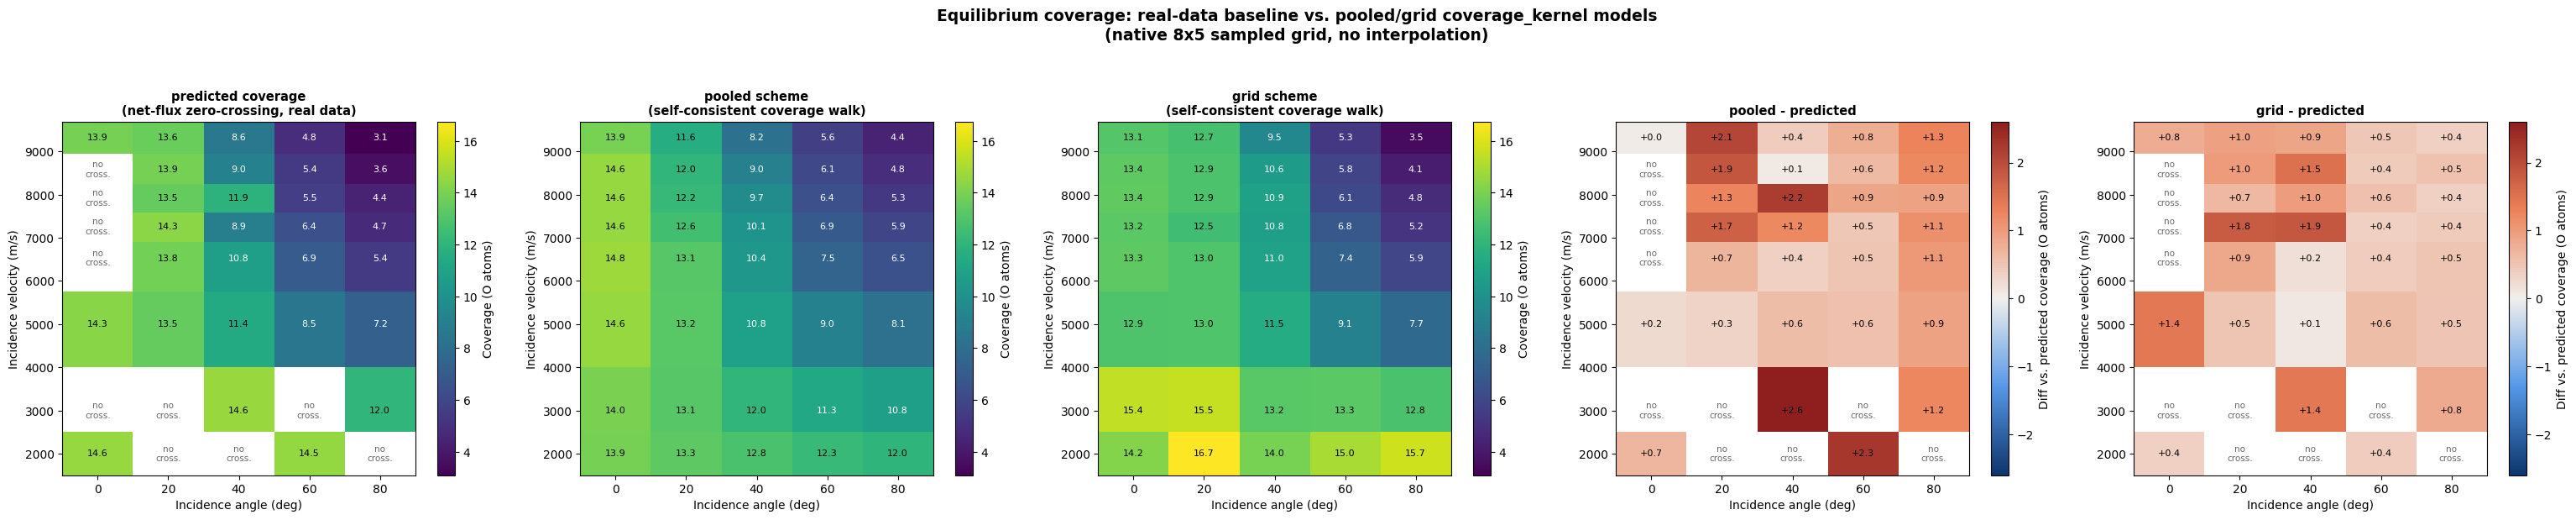

In [6]:
diverging_cmap = mcolors.LinearSegmentedColormap.from_list(
    "blue_red_diverging", ["#0d366b", "#5598e7", "#f0efec", "#ec835a", "#8f1f1e"],
)

fig, axes = plt.subplots(1, 5, figsize=(31, 6.4))

seq_panels = [
    ("predicted coverage\n(net-flux zero-crossing, real data)", predicted),
    ("pooled scheme\n(self-consistent coverage walk)", pooled_grid),
    ("grid scheme\n(self-consistent coverage walk)", grid_grid),
]
vmin = min(np.nanmin(g) for _, g in seq_panels)
vmax = max(np.nanmax(g) for _, g in seq_panels)

for ax, (title, grid) in zip(axes[:3], seq_panels):
    im = ax.pcolormesh(real_angles, real_velocities, grid, cmap="viridis", shading="nearest", vmin=vmin, vmax=vmax)
    for i, velocity in enumerate(real_velocities):
        for j, angle in enumerate(real_angles):
            val = grid[i, j]
            if np.isnan(val):
                ax.text(angle, velocity, "no\ncross.", ha="center", va="center", fontsize=7.5, color="#666")
                continue
            fg = "white" if val < vmin + (vmax - vmin) * 0.6 else "black"
            ax.text(angle, velocity, f"{val:.1f}", ha="center", va="center", fontsize=8, color=fg)
    ax.set_xlabel("Incidence angle (deg)")
    ax.set_ylabel("Incidence velocity (m/s)")
    ax.set_title(title, fontsize=10.5, fontweight="bold")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Coverage (O atoms)")

diff_panels = [("pooled - predicted", diff_pooled), ("grid - predicted", diff_grid)]
diff_max = max(np.nanmax(np.abs(g)) for _, g in diff_panels)

for ax, (title, grid) in zip(axes[3:], diff_panels):
    im = ax.pcolormesh(real_angles, real_velocities, grid, cmap=diverging_cmap, shading="nearest",
                       vmin=-diff_max, vmax=diff_max)
    for i, velocity in enumerate(real_velocities):
        for j, angle in enumerate(real_angles):
            val = grid[i, j]
            if np.isnan(val):
                ax.text(angle, velocity, "no\ncross.", ha="center", va="center", fontsize=7.5, color="#666")
                continue
            ax.text(angle, velocity, f"{val:+.1f}", ha="center", va="center", fontsize=8, color="black")
    ax.set_xlabel("Incidence angle (deg)")
    ax.set_ylabel("Incidence velocity (m/s)")
    ax.set_title(title, fontsize=10.5, fontweight="bold")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Diff vs. predicted coverage (O atoms)")

fig.suptitle("Equilibrium coverage: real-data baseline vs. pooled/grid coverage_kernel models\n"
             "(native 8x5 sampled grid, no interpolation)",
            fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0.02, 1, 0.94])

Path("hyper_plots").mkdir(exist_ok=True)
out_path = Path("hyper_plots") / "coverage_heatmap_native.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
print(f"Saved {out_path}")
plt.show()


## Notes

- This comparison is at the native 8x5 grid only, deliberately not
  interpolated, mirroring `coverage_experiment/coverage_model`'s
  `coverage_heatmap_validation.ipynb`.
- `pooled_model`/`grid_model` here are the ones `train_models.ipynb` saves
  to `models/` -- see that notebook's fit + validation cells for the
  hyperparameter choices (n_knots, C, MC ceiling settings) that went into
  them.
- For extrapolation behavior outside this grid (1000 m/s and
  10000-11000 m/s), see `monte_carlo_walk.ipynb`, which validates the
  11000 m/s column directly against real, held-out MD data.